# Ödev 1 — Veri Temizleme: Çalışanlar (`Calisanlar.xlsx`)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Klasör yolları (notebook, notebooks/ klasöründen çalıştırılır)
RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES = Path("../figures")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
# Dosyada birden fazla sayfa (sheet) var; hangisinin kullanılacağına karar vermeden önce hepsini incele
sheets = pd.read_excel(RAW / "Calisanlar.xlsx", sheet_name=None)
for name, sheet in sheets.items():
    print(f"{name!r}: {sheet.shape}")

'data_cleaning_practice_data (2)': (500, 7)
'data_cleaning_practice_dataset': (500, 1)


## 1. Veriyi Keşfetme ve İlk Analiz

In [3]:
# Ham veri: bu bölümde hiç değiştirilmez, tüm tespitler bunun üzerinde yapılır
ham = sheets["data_cleaning_practice_data (2)"]
ham.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Name        500 non-null    str    
 1   Gender      500 non-null    str    
 2   Age         252 non-null    float64
 3   City        500 non-null    str    
 4   Department  500 non-null    str    
 5   Salary      248 non-null    float64
 6   Email       500 non-null    str    
dtypes: float64(2), str(5)
memory usage: 27.5 KB


In [4]:
import io

# 2. sayfa: aynı verinin CSV metni olarak tek sütuna yazılmış hali (her satır "Name,Gender,Age,..." biçiminde).
# Metin olarak okunuyor (dtype=str): ondalık basamaklar ve boş hücreler dosyada yazıldığı gibi kalsın
ikinci_sayfa = sheets["data_cleaning_practice_dataset"]
orijinal_metin = pd.read_csv(io.StringIO("\n".join([ikinci_sayfa.columns[0], *ikinci_sayfa.iloc[:, 0]])),
                             dtype=str, keep_default_na=False)
orijinal_maas = pd.to_numeric(orijinal_metin["Salary"].replace("", np.nan))
orijinal_metin.head()

,Name,Gender,Age,City,Department,Salary,Email
0,Tariq,Male,47.0,Karachi,Sales,123609.72,tariq76@gmail.com
1,Hina,Female,26.0,Quetta,HR,125683.94,hina90@gmail.com
2,Usman,Male,36.0,lahore,Sales,,usman71@gmail.com
3,Sana,Female,21.0,Quetta,Finance,147901.41,sana72@gmail.com
4,Ayesha,Male,40.0,lahore,HR,123880.8,ayesha25@gmail.com


In [5]:
# Tespit fonksiyonları: veriyi sadece okur, hiçbir şeyi değiştirmez
metin_sutunlari = ham.select_dtypes(include=["object", "string"]).columns


def bosluk_raporu(veri):
    """Her metin sütununda başında / sonunda boşluk olan hücre sayısı."""
    satirlar = []
    for sutun in metin_sutunlari:
        degerler = veri[sutun].dropna().astype(str)
        satirlar.append({
            "Sütun": sutun,
            "Baştaki boşluk": (degerler != degerler.str.lstrip()).sum(),
            "Sondaki boşluk": (degerler != degerler.str.rstrip()).sum(),
        })
    return pd.DataFrame(satirlar)


def harf_raporu(veri):
    """Yalnızca büyük / küçük harf farkı yüzünden ayrı görünen değerler."""
    satirlar = []
    for sutun in metin_sutunlari:
        degerler = veri[sutun].dropna().astype(str)
        for anahtar, grup in degerler.groupby(degerler.str.lower()):
            yazimlar = grup.value_counts()
            if len(yazimlar) > 1:
                satirlar.append({
                    "Sütun": sutun,
                    "Değer": anahtar,
                    "Yazım biçimleri": ", ".join(f"{y!r} ({n})" for y, n in yazimlar.items()),
                    "Kayıt sayısı": len(grup),
                })
    return pd.DataFrame(satirlar, columns=["Sütun", "Değer", "Yazım biçimleri", "Kayıt sayısı"])


# Eksik anlamına gelen yazılar (harften bağımsız karşılaştırılır)
EKSIK_IFADELER = {"na", "n/a", "#n/a", "nan", "null", "none", "nil", "unknown",
                  "missing", "undefined", "bilinmiyor", "yok"}
# Sayısal sütunlarda sık kullanılan yer tutucu sayılar
YER_TUTUCU_SAYILAR = {99, 999, 9999, 99999, 999999}


def metin_eksik_kurallari(degerler):
    """Metin değerleri için gizli eksik kuralları: {neden: hangi değerlerin uyduğu}."""
    normal = degerler.str.strip().str.lower()
    return {
        "eksik ifadesi": normal.isin(EKSIK_IFADELER),
        "harf / rakam yok": ~normal.str.contains(r"[^\W_]"),  # "", "?", "-" gibi
    }


def sayisal_eksik_kurallari(degerler):
    """Sayısal değerler için şüpheli değer kuralları: {neden: hangi değerlerin uyduğu}."""
    return {
        "sıfır veya negatif": degerler <= 0,
        "yer tutucu sayı": degerler.isin(YER_TUTUCU_SAYILAR),
    }


def gizli_eksik_raporu(veri):
    """Null görünmeyen ama eksik anlamına gelebilecek değerler ve kaç kez geçtikleri."""
    kontroller = [(sutun, metin_eksik_kurallari, veri[sutun].dropna().astype(str))
                  for sutun in metin_sutunlari]
    kontroller += [(sutun, sayisal_eksik_kurallari, veri[sutun].dropna())
                   for sutun in veri.select_dtypes(include="number").columns]
    satirlar = []
    for sutun, kurallar, degerler in kontroller:
        for neden, maske in kurallar(degerler).items():
            for deger, sayi in degerler[maske].value_counts().items():
                satirlar.append({"Sütun": sutun, "Değer": repr(deger), "Neden": neden, "Kayıt sayısı": sayi})
    return pd.DataFrame(satirlar, columns=["Sütun", "Değer", "Neden", "Kayıt sayısı"])


def yas_raporu(veri):
    """Age sütununun aralığı ve 10'un katı olan değerlerin oranı (10 ile çarpılmış kayıt belirtisi)."""
    yas = veri["Age"].dropna()
    return pd.DataFrame({
        "Dolu değer": [len(yas)],
        "Farklı değer": [yas.nunique()],
        "En küçük": [yas.min()],
        "En büyük": [yas.max()],
        "10'un katı olan (%)": [100 * (yas % 10 == 0).mean()],
    })

def maas_raporu(veri):
    """Salary değerlerinin 2. sayfadaki metin değerlerine oranı, metindeki ondalık basamak sayısına göre.
    Oran 1 ise değer doğru; 10 veya 100 ise ondalık nokta kaybolmuş."""
    dolu = veri["Salary"].notna()
    ondalik = orijinal_metin.loc[dolu, "Salary"].str.split(".").str[1].fillna("").str.len()
    oran = (veri.loc[dolu, "Salary"] / orijinal_maas[dolu]).round(6)
    return pd.crosstab(ondalik.rename("Ondalık basamak (2. sayfa)"), oran.rename("Oran (Salary / 2. sayfa)"))

In [6]:
# Temizlik fonksiyonları: aldıkları tabloyu değiştirmez, temizlenmiş yeni bir tablo döndürür
def bosluklari_temizle(veri):
    """Metin sütunlarındaki baştaki ve sondaki boşlukları atar."""
    veri = veri.copy()
    for sutun in metin_sutunlari:
        veri[sutun] = veri[sutun].str.strip()
    return veri


def gizli_eksikleri_bosalt(veri):
    """Metin sütunlarında eksik anlamına gelen değerleri NaN'a çevirir.
    Sayısal şüpheli değerlere dokunmaz: onların eksik mi aykırı mı olduğu ayrıca karar gerektirir."""
    veri = veri.copy()
    for sutun in metin_sutunlari:
        degerler = veri[sutun].dropna().astype(str)
        eksik = pd.DataFrame(metin_eksik_kurallari(degerler)).any(axis=1)  # herhangi bir kurala uyan
        veri[sutun] = veri[sutun].mask(eksik.reindex(veri.index, fill_value=False))
    return veri


def harfleri_duzelt(veri):
    """Küçük harfli hali aynı olan değerleri, o gruptaki en sık geçen yazıma çevirir."""
    veri = veri.copy()
    for sutun in metin_sutunlari:
        anahtar = veri[sutun].str.lower()
        en_sik_yazim = veri[sutun].groupby(anahtar).agg(lambda g: g.mode().iloc[0])
        veri[sutun] = anahtar.map(en_sik_yazim)
    return veri


def yasi_ondan_bol(veri):
    """Age değerleri 10 ile çarpılmış kaydedilmiş (200-600); gerçek yaşa (20-60) çevirmek için 10'a böler."""
    veri = veri.copy()
    veri["Age"] = veri["Age"] / 10
    return veri


def maasi_duzelt(veri):
    """Salary değerlerini 2. sayfadaki metin değerleriyle değiştirir. 1. sayfada ondalık nokta kaybolduğu için
    maaşlar 10 veya 100 kat büyük; hangi katsayının uygulandığı 1. sayfadan bilinemediği için bölerek düzeltilemez."""
    veri = veri.copy()
    veri["Salary"] = orijinal_maas
    return veri


def yasi_tamsayi_yap(veri):
    """Age sütununu boş değer tutabilen tam sayı tipine (Int64) çevirir.
    Kesirli yaşlar aşağı yuvarlanır (25.5 -> 25); boş değerler boş kalır."""
    veri = veri.copy()
    veri["Age"] = np.floor(veri["Age"]).astype("Int64")
    return veri

### 1.1 Tespit (ham veri)

In [7]:
bosluk_raporu(ham)

,Sütun,Baştaki boşluk,Sondaki boşluk
0,Name,0,0
1,Gender,0,0
2,City,0,0
3,Department,59,59
4,Email,0,0


In [8]:
# Boşluklar yalnızca karşılaştırma için geçici olarak atılıyor; ham değişmiyor
harf_raporu(bosluklari_temizle(ham))

,Sütun,Değer,Yazım biçimleri,Kayıt sayısı
0,City,islamabad,"'Islamabad' (97), 'islamabad' (9)",106
1,City,karachi,"'Karachi' (87), 'karachi' (10)",97
2,City,lahore,"'Lahore' (81), 'lahore' (10)",91
3,City,peshawar,"'Peshawar' (92), 'peshawar' (12)",104
4,City,quetta,"'Quetta' (93), 'quetta' (9)",102


> **Not:** Gizli eksik değerler puanlamada 2. kriterin (Eksik Verilerin Tespiti) konusu, aynı kontrol 2. bölümde de var. Tekrar eden e-postalı kayıtların karşılaştırması (1.4) bu değerlerin bilinmesine bağlı olduğu için şimdilik burada da çalıştırılıyor.

In [9]:
gizli_eksik_raporu(ham)

,Sütun,Değer,Neden,Kayıt sayısı


In [10]:
# Yaşların hepsi 10'un katıysa ve 200-600 aralığındaysa değerler 10 ile çarpılmış kaydedilmiştir
yas_raporu(ham)

,Dolu değer,Farklı değer,En küçük,En büyük,10'un katı olan (%)
0,252,41,200.0,600.0,100.0


In [11]:
# 2. sayfa 1. sayfayla aynı kayıtları mı içeriyor? Metin sütunlarında değerler, sayısal sütunlarda
# boş hücrelerin yeri satır satır karşılaştırılıyor (500 satırın hepsi eşleşmeli)
pd.DataFrame({
    "Karşılaştırma": ["değer aynı" if sutun in metin_sutunlari else "boş hücre yeri aynı" for sutun in ham.columns],
    "Eşleşen satır": [
        (ham[sutun] == orijinal_metin[sutun]).sum() if sutun in metin_sutunlari
        else (ham[sutun].isna() == (orijinal_metin[sutun] == "")).sum()
        for sutun in ham.columns
    ],
}, index=ham.columns)

,Karşılaştırma,Eşleşen satır
Name,değer aynı,500
Gender,değer aynı,500
Age,boş hücre yeri aynı,500
City,değer aynı,500
Department,değer aynı,500
Salary,boş hücre yeri aynı,500
Email,değer aynı,500


In [12]:
# 1. sayfadaki maaşlar 2. sayfadakilerin kaç katı?
maas_raporu(ham)

Oran (Salary / 2. sayfa),10.0,100.0
Ondalık basamak (2. sayfa),,
1,24,0
2,0,224


> **Ondalık nokta kaybı — `Age` ve `Salary`:** `Age` değerlerinin hepsi 10'un katı ve 200–600 arasında, yani yaşlar 10 kat büyük kaydedilmiş. Nedeni dosyadaki 2. sayfada görülüyor: 2. sayfa, aynı 500 kaydın CSV metni olarak tek sütuna yazılmış hali; metin sütunları satır satır aynı, `Age` ve `Salary`'deki boş hücreler aynı yerlerde. 1. sayfa, bu metin noktayı binlik ayırıcı sayan bir bölge ayarıyla (örneğin Türkçe Excel) açılırken oluşmuş ve ondalık nokta silinmiş: `47.0` → 470. Yaşların hepsi `.0` ile bittiği için katsayı her değerde 10'dur ve 10'a bölmek yeterlidir (`yasi_ondan_bol`). Aynı sorun `Salary` da var: 1. sayfadaki maaşların hepsi tam sayı; 2. sayfada iki ondalık basamağı olan 224 değer 100 kat (`123609.72` → 12360972), tek ondalık basamağı olan 24 değer 10 kat (`123880.8` → 1238808) büyümüş. Maaşlarda katsayı değere göre değiştiği için 1. sayfadaki bir değerin 10 ile mi 100 ile mi çarpıldığı tek başına bilinemez (1238808, 123880,8 de olabilir 12388,08 de). Bu nedenle `maasi_duzelt` maaşları bölerek değil, 2. sayfadaki metin değerlerinden alarak düzeltir. Gerçek maaşlar 25.041,66 – 149.978,29 arasındadır.

> **Yanlış veri tipi — `Age`:** Yaş tam sayı olmalı, ancak sütun `float64` olarak okunuyor. Pandas'ın klasik `int64` tipi boş değer (NaN) tutamadığı için, boş hücre içeren tam sayı sütunları ondalıklı tipe çevrilir. Düzeltme için `yasi_tamsayi_yap` fonksiyonu tanımlandı (boş değer tutabilen `Int64` tipine çevirir, kesirli yaşları aşağı yuvarlar). Fonksiyon 1.2'deki temizlik zincirine eklenmedi; kaydetmeden hemen önce (6. bölüm) uygulanıyor. Bunun iki nedeni var:
> 1. **Tip farkı analizi etkilemiyor.** Yaşlar 10'a bölündükten sonra hepsi zaten tam sayı; ortalama, standart sapma, IQR, z-skoru ve korelasyon iki tipte de aynı sonucu verir. Analizi etkileyen asıl sorun olan 10 kat ölçek (`yasi_ondan_bol`) zincirin başında düzeltiliyor.
> 2. **Erken dönüşüm sonraki adımları bozuyor.** `Int64` sütunundaki boş değerler, statsmodels ile kurulan R² modellerinde (3.1) hataya yol açıyor; ortalama ile doldurmada (3.2) ise ondalıklı ortalama (≈ 40,42) tam sayı sütununa yazılamıyor.
>
> Doldurmadan sonra boş ve kesirli değer kalmadığı için dönüşüm, hiçbir değeri değiştirmeden yalnızca tipi düzeltiyor.

### 1.2 Temizlik

In [13]:
# ham'dan yeni bir tablo üret: boşlukları temizle, gizli eksikleri NaN yap, harfleri düzelt, yaşı 10'a böl, maaşı 2. sayfadan al
df = (
    ham
    .pipe(bosluklari_temizle)
    .pipe(gizli_eksikleri_bosalt)
    .pipe(harfleri_duzelt)
    .pipe(yasi_ondan_bol)
    .pipe(maasi_duzelt)
)

### 1.3 Doğrulama (temizlenmiş veri)

In [14]:
# Bütün sayılar 0 olmalı
bosluk_raporu(df)

,Sütun,Baştaki boşluk,Sondaki boşluk
0,Name,0,0
1,Gender,0,0
2,City,0,0
3,Department,0,0
4,Email,0,0


In [15]:
# Tablo boş olmalı
harf_raporu(df)

,Sütun,Değer,Yazım biçimleri,Kayıt sayısı


In [16]:
# Metin kurallarına uyan satır kalmamalı (sayısal şüpheliler bilerek çevrilmiyor, varsa burada görünür)
gizli_eksik_raporu(df)

,Sütun,Değer,Neden,Kayıt sayısı


In [17]:
# Yaşlar 20-60 aralığında olmalı; dolu değer sayısı değişmemeli
yas_raporu(df)

,Dolu değer,Farklı değer,En küçük,En büyük,10'un katı olan (%)
0,252,41,20.0,60.0,9.52381


In [18]:
# Bütün dolu maaşlarda oran 1 olmalı
maas_raporu(df)

Oran (Salary / 2. sayfa),1.0
Ondalık basamak (2. sayfa),
1,24
2,224


### 1.4 Tekrar eden e-postalar

In [19]:
# Temizlenmiş veri üzerinde: harf ve boşluk farkları zaten giderildiği için ek normalleştirme gerekmiyor
eposta = df["Email"].dropna()
tekrar_sayilari = eposta.value_counts()
tekrar_eden_epostalar = tekrar_sayilari[tekrar_sayilari > 1]

print(f"Boş olmayan e-posta: {len(eposta)}")
print(f"Farklı e-posta: {eposta.nunique()}")
print(f"Birden fazla kayıtta geçen e-posta: {len(tekrar_eden_epostalar)} "
      f"(toplam {tekrar_eden_epostalar.sum()} kayıt)")

tekrar_eden_epostalar.rename_axis("Email").reset_index(name="Kayıt sayısı")

Boş olmayan e-posta: 500
Farklı e-posta: 408
Birden fazla kayıtta geçen e-posta: 75 (toplam 167 kayıt)


,Email,Kayıt sayısı
0,ayesha95@gmail.com,5
1,tariq82@gmail.com,5
2,hina58@gmail.com,4
3,ahmed44@gmail.com,3
4,tariq17@gmail.com,3
...,...,...
70,sara54@gmail.com,2
71,ali98@gmail.com,2
72,sara44@gmail.com,2
73,sana53@gmail.com,2


In [20]:
# Aynı e-postaya sahip kayıtları karşılaştır. Null "bilinmiyor" sayılır, hiçbir değerle çelişmez:
# bir grupta her sütunda en fazla bir farklı dolu değer varsa o sütun tutarlıdır (nunique null'ları saymaz).
diger_sutunlar = df.columns.drop("Email")
tekrarlar = df[df["Email"].notna() & df["Email"].duplicated(keep=False)]
gruplar = tekrarlar.groupby("Email")

celisen = gruplar[diger_sutunlar].nunique().gt(1)  # iki veya daha fazla farklı dolu değer
bos_var = tekrarlar[diger_sutunlar].isna().groupby(tekrarlar["Email"]).any()

eposta_raporu = pd.DataFrame({
    "Kayıt sayısı": gruplar.size(),
    "Kategori": pd.Series(
        np.select([celisen.any(axis=1), bos_var.any(axis=1)], ["çelişkili", "null dışında aynı"], default="tamamen aynı"),
        index=celisen.index,
    ),
    "Çelişen sütunlar": celisen.apply(lambda satir: ", ".join(satir.index[satir]), axis=1),
    "Boş içeren sütunlar": bos_var.apply(lambda satir: ", ".join(satir.index[satir]), axis=1),
})

print(eposta_raporu["Kategori"].value_counts().to_string(), end="\n\n")
eposta_raporu.sort_values(["Kategori", "Email"])

Kategori
çelişkili            73
null dışında aynı     2



,Kayıt sayısı,Kategori,Çelişen sütunlar,Boş içeren sütunlar
Email,,,,
ahmed80@gmail.com,2,null dışında aynı,,"Age, Salary"
sara60@gmail.com,2,null dışında aynı,,"Age, Salary"
ahmed13@gmail.com,3,çelişkili,"Gender, Age, City, Department",Salary
ahmed2@gmail.com,2,çelişkili,"City, Department","Age, Salary"
ahmed35@gmail.com,2,çelişkili,"Gender, Age, Department, Salary",
...,...,...,...,...
zara3@gmail.com,2,çelişkili,"Gender, Age, City, Department",Salary
zara63@gmail.com,2,çelişkili,"Age, City, Department, Salary",
zara69@gmail.com,2,çelişkili,"City, Department","Age, Salary"


In [21]:
# Boş değer içeren gruplardaki kayıtların tamamı: boşlukların gruptaki hangi değerlerle "eşleştiğini" görmek için
bos_iceren_epostalar = eposta_raporu.index[eposta_raporu["Boş içeren sütunlar"] != ""]
(
    tekrarlar[tekrarlar["Email"].isin(bos_iceren_epostalar)]
    .join(eposta_raporu["Kategori"], on="Email")
    .sort_values(["Kategori", "Email"])
)

,Name,Gender,Age,City,Department,Salary,Email,Kategori
53,Ahmed,Female,57.0,Lahore,IT,NaN,ahmed80@gmail.com,null dışında aynı
498,Ahmed,Female,NaN,Lahore,IT,82915.36,ahmed80@gmail.com,null dışında aynı
148,Sara,Male,NaN,Quetta,Finance,38112.70,sara60@gmail.com,null dışında aynı
370,Sara,Male,25.0,Quetta,Finance,NaN,sara60@gmail.com,null dışında aynı
270,Ahmed,Male,39.0,Quetta,HR,104732.77,ahmed13@gmail.com,çelişkili
...,...,...,...,...,...,...,...,...
423,Zara,Female,52.0,Karachi,Finance,NaN,zara97@gmail.com,çelişkili
427,Zara,Female,NaN,Quetta,Marketing,109164.25,zara97@gmail.com,çelişkili
73,Zara,Female,NaN,Karachi,HR,NaN,zara99@gmail.com,çelişkili
124,Zara,Female,45.0,Quetta,Sales,50212.98,zara99@gmail.com,çelişkili


> **Karar — tekrar eden e-postalar:** Aynı e-postaya sahip 75 grubun 73'ü en az bir sütunda çelişiyor; yani bu kayıtlar aynı kişinin tekrar eden kayıtları değil, aynı e-posta adresini paylaşan farklı kişiler. Boş değerler dışında tutarlı olan 2 grupta da kayıtları birbirine bağlayan tek şey cinsiyet, şehir ve departmanın aynı olması (ad zaten e-postanın bir parçası olduğu için her grupta aynı); bu kadar az sütun tesadüfen de eşleşebileceği için bu gruplar da farklı kişiler olarak değerlendirildi. Aynı e-posta, kayıtların aynı kişiye ait olduğunu göstermediği için bu kayıtlara dokunulmadı; hiçbir satır silinmedi veya birleştirilmedi.

## 2. Eksik Verilerin Tespiti ve Görselleştirilmesi

In [22]:
gizli_eksik_raporu(ham)

,Sütun,Değer,Neden,Kayıt sayısı


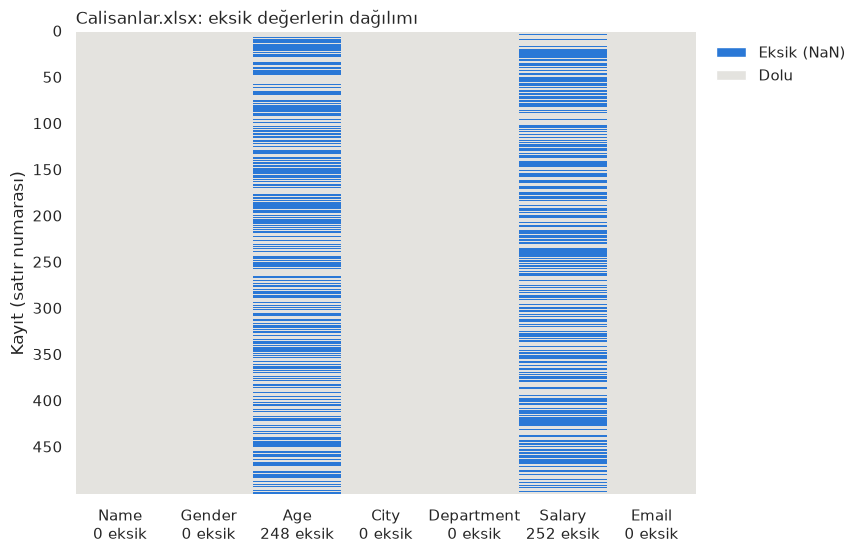

In [23]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Görünür eksik değerler (NaN): her satır bir kayıt, her sütun bir değişken
DOLU_RENK, EKSIK_RENK = "#e4e3df", "#2a78d6"
eksik = ham.isna()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(eksik.astype(int), cmap=ListedColormap([DOLU_RENK, EKSIK_RENK]), vmin=0, vmax=1,
            cbar=False, yticklabels=50, ax=ax)
ax.set_xticklabels([f"{sutun}\n{sayi} eksik" for sutun, sayi in eksik.sum().items()], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("Kayıt (satır numarası)")
ax.tick_params(axis="y", rotation=0)
ax.set_title("Calisanlar.xlsx: eksik değerlerin dağılımı", loc="left")
ax.legend(handles=[Patch(facecolor=EKSIK_RENK, label="Eksik (NaN)"),
                   Patch(facecolor=DOLU_RENK, label="Dolu")],
          loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

fig.savefig(FIGURES / "calisanlar_eksik_isi_haritasi.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
# Eksik hücrelerin sütunlara ve satırlara dağılımı (gizli eksik olmadığı için görünür NaN'lar bütün eksikleri kapsıyor)
eksik_iceren_sutunlar = eksik.columns[eksik.any()]
print(f"En az bir değeri eksik olan satır: {eksik.any(axis=1).sum()} / {len(eksik)}")
print(f"{' ve '.join(eksik_iceren_sutunlar)} değerleri birlikte eksik olan satır: {eksik[eksik_iceren_sutunlar].all(axis=1).sum()}")
pd.DataFrame({
    "Eksik hücre": eksik[eksik_iceren_sutunlar].sum(),
    "Eksik oranı (%)": 100 * eksik[eksik_iceren_sutunlar].mean(),
})

En az bir değeri eksik olan satır: 376 / 500
Age ve Salary değerleri birlikte eksik olan satır: 124


,Eksik hücre,Eksik oranı (%)
Age,248,49.6
Salary,252,50.4


In [25]:
from scipy import stats

# Eksiklik bir gruba ya da diğer sütunun eksikliğine bağlı mı? Her satır bir ki-kare bağımsızlık testi:
# p değeri büyükse (> 0,05) eksik olup olmama ile karşılaştırılan sütun arasında anlamlı bir ilişki yoktur.
# Gruplar temizlenmiş df'ten alınıyor ("lahore" / "Lahore" ayrı grup sayılmasın); eksik hücreler ham ile aynı.
karsilastirmalar = [(sutun, grup, df[grup]) for sutun in eksik_iceren_sutunlar for grup in ["Gender", "City", "Department"]]
karsilastirmalar.append(("Age", "Salary eksik mi", df["Salary"].isna()))

satirlar = []
for sutun, ad, karsi in karsilastirmalar:
    tablo = pd.crosstab(df[sutun].isna(), karsi)
    satirlar.append({"Eksik sütun": sutun, "Karşılaştırılan": ad, "p değeri": stats.chi2_contingency(tablo).pvalue})
pd.DataFrame(satirlar).round(3)

,Eksik sütun,Karşılaştırılan,p değeri
0,Age,Gender,0.649
1,Age,City,0.431
2,Age,Department,0.690
3,Salary,Gender,1.000
4,Salary,City,0.254
5,Salary,Department,0.465
6,Age,Salary eksik mi,0.930


> **Eksik veriler:** Gizli eksik değer bulunmadı: metin sütunlarında eksik anlamına gelen yazılar (`"N/A"`, `"?"`, boş metin vb.), sayısal sütunlarda sıfır, negatif veya yer tutucu sayılar yok. 1.1'deki sayfa karşılaştırması da `Age` ve `Salary`'deki boş hücrelerin 2. sayfadaki metinde de boş olduğunu gösteriyor. Yani eksikler yalnızca görünür boş hücrelerden oluşuyor ve yalnızca iki sayısal sütunda: `Age`'de 248 (%49,6), `Salary`'de 252 (%50,4) hücre eksik. 124 satırda iki değer birlikte eksik; 376 satırda (%75,2) en az biri eksik, yani yalnızca 124 satır tam.
>
> Isı haritasında eksik hücreler satırlara düzensiz dağılmış, belirli bir satır aralığında yoğunlaşmıyor. Ki-kare testleri de bunu destekliyor: `Age` ve `Salary`'nin eksik olup olmaması cinsiyet, şehir ve departmanla ilişkili değil (bütün p değerleri ≥ 0,25), iki sütunun eksikliği de birbirinden bağımsız (p = 0,93). Bu sonuç eksikliğin tamamen rastgele (MCAR) olduğunu kanıtlamaz, ama bu varsayımla çelişen bir bulgu da yok. 3. bölümde kullanılan rastgele örneklemeyle doldurma bu varsayıma dayanır: eksik hücreler, dolu değerlerle aynı dağılımdan geliyormuş gibi doldurulur.

## 3. Eksik Veri Stratejisi ve Uygulama

> **Neden silme değil, doldurma:** Eksik değer içeren satırları silmek bu veride uygulanabilir değil. 2. bölümde görüldüğü gibi 500 satırın 376'sında (%75,2) en az bir değer eksik, yani yalnızca 124 satır tam. Bu satırlar silinirse verinin dörtte üçü kaybolur. Üstelik bu satırlarda `Name`, `Gender`, `City`, `Department` ve `Email` sütunlarının hepsi dolu olduğu için, tek bir sayısal değerin eksikliği yüzünden eksiksiz bilgiler de atılmış olur. Eksiklik rastgele göründüğü için (2. bölüm) silmek sonuçları sistematik olarak saptırmazdı, ama örneklem 500'den 124'e iner ve bütün istatistikler çok daha belirsiz hale gelir. `Age` ve `Salary` sütunlarını silmek de bir seçenek değil: yaklaşık yarıları eksik olsa da verinin sayısal sütunları yalnızca bu ikisi ve analiz edilecek bilginin kendisi bu sütunlarda. Bu nedenle eksik değerler silinmek yerine dolduruldu.

### 3.1 Ön kontrol: diğer sütunlar `Age` ve `Salary`'yi açıklıyor mu?

In [26]:
import statsmodels.formula.api as smf

# Diğer sütunlar Age ve Salary'yi açıklıyor mu? (KNN ve regresyonla doldurmanın ön koşulu)
# Her model yalnızca kullandığı sütunların hepsi dolu olan satırlarla kurulur.
eksik_sutunlar = ["Age", "Salary"]
kategorikler = "C(Gender) + C(City) + C(Department)"
modeller = {
    "Age ~ kategorikler": f"Age ~ {kategorikler}",
    "Age ~ kategorikler + Salary": f"Age ~ {kategorikler} + Salary",
    "Salary ~ kategorikler": f"Salary ~ {kategorikler}",
    "Salary ~ kategorikler + Age": f"Salary ~ {kategorikler} + Age",
}
r2_tablosu = pd.DataFrame([
    {"Model": ad, "Satır sayısı": int(sonuc.nobs), "R²": sonuc.rsquared, "Düzeltilmiş R²": sonuc.rsquared_adj}
    for ad, sonuc in ((ad, smf.ols(formul, data=df).fit()) for ad, formul in modeller.items())
]).set_index("Model")
r2_tablosu.round(3)

,Satır sayısı,R²,Düzeltilmiş R²
Model,,,
Age ~ kategorikler,252,0.038,0.002
Age ~ kategorikler + Salary,124,0.081,0.000
Salary ~ kategorikler,248,0.018,-0.019
Salary ~ kategorikler + Age,124,0.027,-0.059


> **KNN ve regresyonla doldurma neden kullanılmadı:** KNN, eksik bir değeri diğer sütunlarda o kayda en çok benzeyen *k* kaydın ortalamasıyla doldurur. Bu yaklaşım ancak benzerliğin ölçüldüğü sütunlar hedef sütunla ilişkiliyse anlamlıdır. Yukarıdaki doğrusal modeller, `Gender`, `City` ve `Department` (ve diğer sayısal sütun) birlikte kullanıldığında bile `Age` ve `Salary`'deki değişimin neredeyse hiçbirini açıklamadığını gösteriyor: düzeltilmiş R² değerleri 0'a çok yakın (en yüksek 0,002), bazıları negatif. Bu durumda KNN'in bulacağı "en yakın komşular" rastgele seçilmiş kayıtlardan farksız olur; doldurulan değerler rastgele *k* değerin ortalamasına, dolayısıyla genel ortalamaya yakınsar ve dağılımı daraltır. Aynı gerekçe regresyonla doldurma için de geçerlidir: R² ≈ 0 olan bir modelin tahminleri pratikte genel ortalamadır. Bu nedenle iki yöntem de karşılaştırmaya alınmadı.

### 3.2 Yöntem karşılaştırması: ortalama, medyan, rastgele örnekleme

In [27]:
# Doldurma fonksiyonları: aldıkları tabloyu değiştirmez, doldurulmuş yeni bir tablo döndürür
def ortalama_ile_doldur(veri):
    """Eksik hücreleri sütunun ortalamasıyla doldurur."""
    veri = veri.copy()
    for sutun in eksik_sutunlar:
        veri[sutun] = veri[sutun].fillna(veri[sutun].mean())
    return veri


def medyan_ile_doldur(veri):
    """Eksik hücreleri sütunun medyanıyla doldurur."""
    veri = veri.copy()
    for sutun in eksik_sutunlar:
        veri[sutun] = veri[sutun].fillna(veri[sutun].median())
    return veri


def rastgele_ornekle_doldur(veri, seed=42):
    """Eksik hücreleri, aynı sütunun dolu değerlerinden rastgele (yerine koyarak) seçilen değerlerle doldurur.
    Sabit seed: her çalıştırmada aynı sonuç."""
    veri = veri.copy()
    rng = np.random.default_rng(seed)
    for sutun in eksik_sutunlar:
        eksik = veri[sutun].isna()
        veri.loc[eksik, sutun] = rng.choice(veri[sutun].dropna().to_numpy(), size=eksik.sum())
    return veri


yontemler = {
    "Ortalama": ortalama_ile_doldur,
    "Medyan": medyan_ile_doldur,
    "Rastgele örnekleme": rastgele_ornekle_doldur,
}
doldurulmus = {ad: yontem(df) for ad, yontem in yontemler.items()}

In [28]:
def dagilim_ozeti(orijinal, tablolar):
    """Orijinal tablodaki dolu (gözlenen) değerler ve verilen her tablo için ortalama, std ve std'deki değişim (%)."""
    ozet = {"Orijinal (dolu değerler)": orijinal[eksik_sutunlar]} | {ad: v[eksik_sutunlar] for ad, v in tablolar.items()}
    karsilastirma = pd.concat({ad: v.agg(["mean", "std"]).T.stack() for ad, v in ozet.items()}, axis=1).T
    karsilastirma.columns = [f"{sutun} {'ortalama' if olcu == 'mean' else 'std'}" for sutun, olcu in karsilastirma.columns]
    for sutun in eksik_sutunlar:
        orijinal_std = orijinal[sutun].std()
        karsilastirma[f"{sutun} std değişimi (%)"] = 100 * (karsilastirma[f"{sutun} std"] / orijinal_std - 1)
    return karsilastirma.round(1)


# Her yöntemden sonra ortalama ve standart sapma
dagilim_ozeti(df, doldurulmus)

,Age ortalama,Age std,Salary ortalama,Salary std,Age std değişimi (%),Salary std değişimi (%)
Orijinal (dolu değerler),40.4,11.4,90342.6,37810.5,0.0,0.0
Ortalama,40.4,8.1,90342.6,26601.8,-29.1,-29.6
Medyan,40.7,8.1,92214.5,26666.7,-29.0,-29.5
Rastgele örnekleme,40.3,11.6,88516.5,38372.9,2.4,1.5


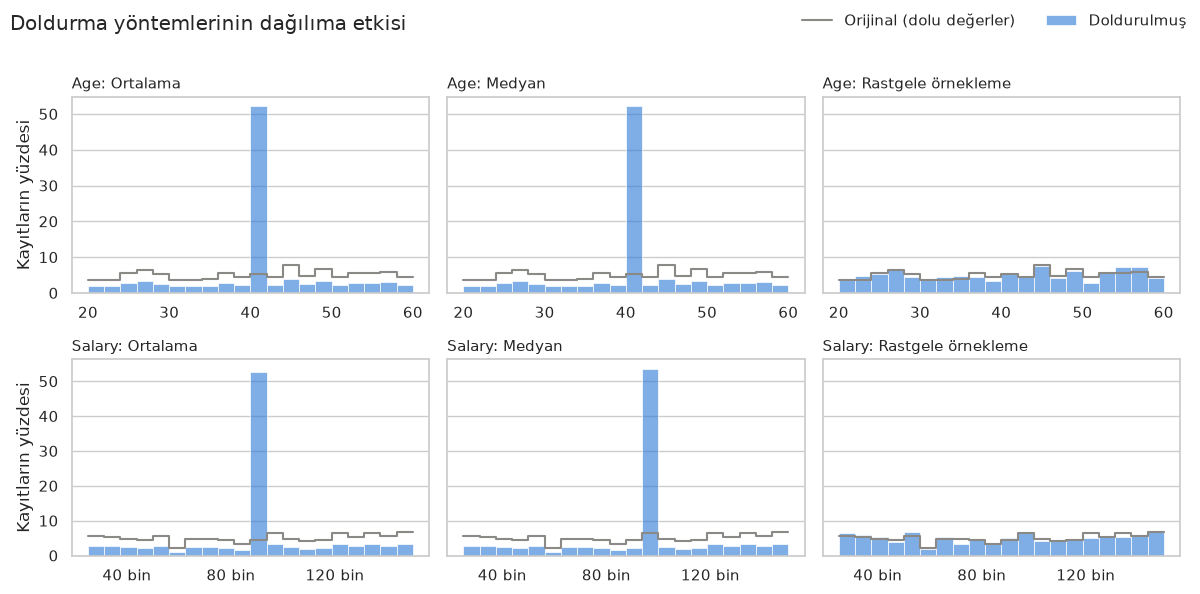

In [29]:
from matplotlib.ticker import FuncFormatter, MaxNLocator

ORIJINAL_RENK, DOLDURULMUS_RENK = "#8a8985", "#2a78d6"


def dagilim_grafigi(orijinal, tablolar, etiket, baslik, figsize=(12, 6)):
    """Her satır bir sütun, her kolon bir tablo. Her panelde orijinal tablodaki dolu değerlerin dağılımı
    (gri çizgi) ve o tablodaki dağılım (mavi) aynı kutularla üst üste çizilir."""
    fig, axes = plt.subplots(len(eksik_sutunlar), len(tablolar), figsize=figsize, sharey="row", squeeze=False)
    for satir, sutun in enumerate(eksik_sutunlar):
        kutular = np.histogram_bin_edges(orijinal[sutun].dropna(), bins=20)  # aynı satırdaki paneller aynı kutuları kullanır
        for kolon, (ad, veri) in enumerate(tablolar.items()):
            ax = axes[satir, kolon]
            sns.histplot(veri[sutun], bins=kutular, stat="percent", color=DOLDURULMUS_RENK, alpha=0.6,
                         edgecolor="white", linewidth=0.5, ax=ax, label=etiket)
            sns.histplot(orijinal[sutun].dropna(), bins=kutular, stat="percent", element="step", fill=False,
                         color=ORIJINAL_RENK, linewidth=1.5, ax=ax, label="Orijinal (dolu değerler)")
            ax.set_title(f"{sutun}: {ad}", loc="left", fontsize=11)
            ax.set_xlabel("")
            ax.set_ylabel("Kayıtların yüzdesi" if kolon == 0 else "")
            ax.grid(axis="x", visible=False)
            if sutun == "Salary":
                ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e3:g} bin"))
                ax.xaxis.set_major_locator(MaxNLocator(4))
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False)
    fig.suptitle(baslik, x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    return fig


fig = dagilim_grafigi(df, doldurulmus, etiket="Doldurulmuş", baslik="Doldurma yöntemlerinin dağılıma etkisi")
fig.savefig(FIGURES / "calisanlar_doldurma_karsilastirmasi.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Seçim ve uygulama

> **Seçilen yöntem: rastgele örnekleme.** Ortalama ve medyanla doldurma, her iki sütunda da kayıtların yaklaşık yarısını tek bir değere eşitliyor: histogramda yapay bir tepe oluşuyor ve standart sapma yaklaşık %29 düşüyor (tablo ve grafik). Dağılımlar simetrik olduğu için ortalama ile medyan arasında pratik bir fark yok; ikisi de dağılımı aynı ölçüde bozuyor. Rastgele örneklemede her eksik hücreye aynı sütunun gözlenen değerlerinden rastgele biri atandığı için dağılımın şekli korunuyor; ortalama ve standart sapmadaki değişim birkaç yüzdeyle sınırlı ve örneklemenin rastgeleliğinden kaynaklanıyor. Yöntemin bilinen sınırlılığı, sütunlar arasındaki ilişkileri hesaba katmamasıdır; bu veride hiçbir sütun yaşı ve maaşı açıklamadığından (3.1) bu sınırlılık sonucu etkilemiyor ve daha karmaşık bir yöntemin yararlanabileceği ek bir bilgi de bulunmuyor. Tekrarlanabilirlik için rastgele sayı üreteci sabit bir başlangıç değeriyle (`seed=42`) çalıştırılıyor.

In [30]:
# Seçilen yöntem uygulanıyor; df değişmiyor, sonuç yeni bir tabloya yazılıyor
df_doldurulmus = rastgele_ornekle_doldur(df)

# Kontrol: eksik hücre kalmamalı
df_doldurulmus[eksik_sutunlar].isna().sum()

Age       0
Salary    0
dtype: int64

## 4. Aykırı Değer (Outlier) Analizi

In [31]:
# Aykırı değer tespit fonksiyonları: veriyi sadece okur, hiçbir şeyi değiştirmez
Z_ESIGI = 3


def iqr_sinirlari(degerler, k=1.5):
    """IQR yöntemi: Q1 - 1.5·IQR altındaki ve Q3 + 1.5·IQR üstündeki değerler aykırıdır."""
    q1, q3 = degerler.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def z_sinirlari(degerler, esik=Z_ESIGI):
    """Z-skoru yöntemi: ortalamadan esik kadar standart sapmadan uzak (|z| > esik) değerler aykırıdır."""
    ortalama, std = degerler.mean(), degerler.std()
    return ortalama - esik * std, ortalama + esik * std


def aykiri_deger_raporu(veri):
    """Her sayısal sütun için iki yöntemin sınırları ve sınırların dışında kalan kayıt sayısı."""
    satirlar = []
    for sutun in veri.select_dtypes("number").columns:
        degerler = veri[sutun].dropna()
        iqr_alt, iqr_ust = iqr_sinirlari(degerler)
        z = (degerler - degerler.mean()) / degerler.std()
        satirlar.append({
            "Sütun": sutun,
            "En küçük": degerler.min(),
            "En büyük": degerler.max(),
            "IQR alt sınır": iqr_alt,
            "IQR üst sınır": iqr_ust,
            "IQR aykırı": ((degerler < iqr_alt) | (degerler > iqr_ust)).sum(),
            "En büyük |z|": z.abs().max(),
            f"Z aykırı (|z| > {Z_ESIGI})": (z.abs() > Z_ESIGI).sum(),
        })
    return pd.DataFrame(satirlar).round(2)


# Doldurulmuş veri üzerinde: rastgele örnekleme yalnızca gözlenen değerleri kopyaladığı için yeni bir uç değer üretmez
aykiri_deger_raporu(df_doldurulmus)

,Sütun,En küçük,En büyük,IQR alt sınır,IQR üst sınır,IQR aykırı,En büyük |z|,Z aykırı (|z| > 3)
0,Age,20.00,60.00,-1.5,82.50,0,1.75,0
1,Salary,25041.66,149978.29,-53032.2,229867.91,0,1.65,0


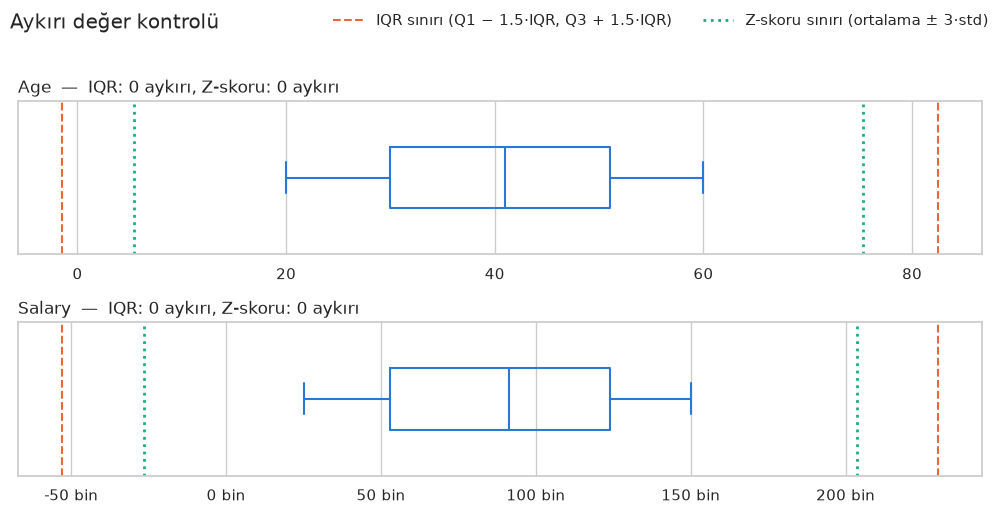

In [32]:
from matplotlib.lines import Line2D

# Kutu grafiği: bıyıklar en fazla 1.5·IQR uzanır, dışında kalan noktalar IQR'a göre aykırıdır.
# Kesikli çizgiler iki yöntemin sınırlarını gösterir; sınırların dışında kalan kayıt yoksa veri aykırı değer içermiyor.
KUTU_RENK, IQR_RENK, Z_RENK = "#2a78d6", "#eb6834", "#1baf7a"
sayisal_sutunlar = df_doldurulmus.select_dtypes("number").columns
rapor = aykiri_deger_raporu(df_doldurulmus).set_index("Sütun")

fig, axes = plt.subplots(len(sayisal_sutunlar), 1, figsize=(10, 2.6 * len(sayisal_sutunlar)))
for ax, sutun in zip(axes, sayisal_sutunlar):
    degerler = df_doldurulmus[sutun]
    sns.boxplot(x=degerler, color=KUTU_RENK, width=0.4, fill=False, linewidth=1.5, ax=ax)
    for sinir in iqr_sinirlari(degerler):
        ax.axvline(sinir, color=IQR_RENK, linestyle="--", linewidth=1.5)
    for sinir in z_sinirlari(degerler):
        ax.axvline(sinir, color=Z_RENK, linestyle=":", linewidth=2)
    ax.set_title(f"{sutun}  —  IQR: {rapor.loc[sutun, 'IQR aykırı']} aykırı, "
                 f"Z-skoru: {rapor.loc[sutun, f'Z aykırı (|z| > {Z_ESIGI})']} aykırı", loc="left")
    ax.set_xlabel("")
axes[-1].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e3:g} bin"))

fig.legend(handles=[
    Line2D([], [], color=IQR_RENK, linestyle="--", linewidth=1.5, label="IQR sınırı (Q1 − 1.5·IQR, Q3 + 1.5·IQR)"),
    Line2D([], [], color=Z_RENK, linestyle=":", linewidth=2, label=f"Z-skoru sınırı (ortalama ± {Z_ESIGI}·std)"),
], loc="upper right", ncols=2, frameon=False)
fig.suptitle("Aykırı değer kontrolü", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.96))

fig.savefig(FIGURES / "calisanlar_aykiri_deger_kutu_grafigi.png", dpi=150, bbox_inches="tight")
plt.show()

> **Karar — aykırı değerler:** `Age` ve `Salary` sütunları IQR yöntemiyle (Q1 − 1.5·IQR, Q3 + 1.5·IQR) ve Z-skoru yöntemiyle (|z| > 3) incelendi; iki yöntem de iki sütunda da aykırı değer bulmadı. Tüm değerler iki yöntemin sınırlarının epey içinde kalıyor: ortalamadan en uzak değer bile yalnızca 1,75 standart sapma uzakta, kutu grafiğinde bıyıkların dışında kalan nokta yok. Bunun nedeni iki dağılımın da belirgin bir kuyruğu olmayan, yaklaşık düzgün dağılımlar olması (yaş 20–60, maaş yaklaşık 25 bin – 150 bin). IQR alt sınırlarının negatif çıkması (yaş −1,5, maaş yaklaşık −53 bin) formülün sonucudur ve gerçekte bir anlam taşımaz; en küçük değerler bu sınırların çok üstünde olduğu için sonucu etkilemez. Sıfır, negatif veya yer tutucu sayı gibi şüpheli sayısal değerler de 1. ve 2. bölümdeki kontrollerde bulunmamıştı. Bu nedenle hiçbir kayıt silinmedi veya sınırlandırılmadı.

## 5. Temizlik Sonrası Dağılım Kontrolü

In [33]:
# Orijinal: df'teki dolu değerler (yaşların 10'a bölünmüş hali; ham'daki 10 kat ölçek karşılaştırmayı anlamsız kılar).
# Son tablo: bütün temizlik adımlarından sonraki tablo (aykırı değer adımı veriyi değiştirmediği için df_doldurulmus)
son_tablo = {"Son tablo": df_doldurulmus}
dagilim_ozeti(df, son_tablo)

,Age ortalama,Age std,Salary ortalama,Salary std,Age std değişimi (%),Salary std değişimi (%)
Orijinal (dolu değerler),40.4,11.4,90342.6,37810.5,0.0,0.0
Son tablo,40.3,11.6,88516.5,38372.9,2.4,1.5


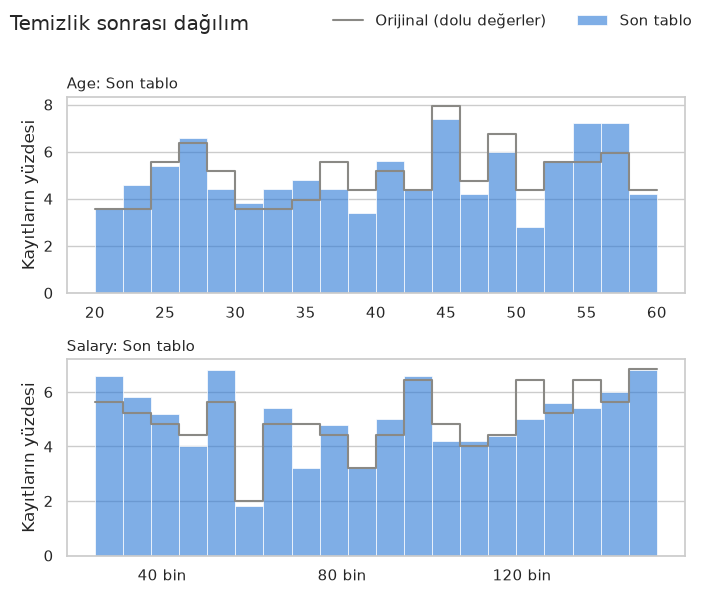

In [34]:
fig = dagilim_grafigi(df, son_tablo, etiket="Son tablo", baslik="Temizlik sonrası dağılım", figsize=(7, 6))
fig.savefig(FIGURES / "calisanlar_temizlik_sonrasi_dagilim.png", dpi=150, bbox_inches="tight")
plt.show()

In [35]:
# Rastgele örnekleme her sütunu ayrı doldurduğu için sütunlar arası ilişkiyi korumaz (3.3'teki sınırlılık).
# Kontrol: Age ile Salary arasındaki korelasyon temizlikten önce ve sonra; p değeri ilişkinin anlamlı olup olmadığını gösterir
korelasyon_tablolari = {
    "Orijinal (iki sütunu da dolu satırlar)": df[eksik_sutunlar].dropna(),
    "Son tablo": df_doldurulmus,
}
satirlar = []
for ad, veri in korelasyon_tablolari.items():
    sonuc = stats.pearsonr(veri["Age"], veri["Salary"])
    satirlar.append({"Tablo": ad, "Satır sayısı": len(veri), "Pearson r": sonuc.statistic, "p değeri": sonuc.pvalue})
pd.DataFrame(satirlar).set_index("Tablo").round(3)

,Satır sayısı,Pearson r,p değeri
Tablo,,,
Orijinal (iki sütunu da dolu satırlar),124,-0.040,0.659
Son tablo,500,-0.022,0.631


> **Sonuç — temizlik sonrası dağılım:** Son tabloda (`df_doldurulmus`) `Age` ve `Salary`'nin ortalaması ve standart sapması orijinal dolu değerlere çok yakın: standart sapma `Age`'de %2,4, `Salary`'de %1,5 artıyor; ortalama `Age`'de 40,4'ten 40,3'e, `Salary`'de 90,3 bin'den 88,5 bin'e (yaklaşık %2) iniyor. Histogramlarda dağılımın şekli korunuyor; ortalama veya medyanla doldurmada görülen yapay tepe yok. Bu küçük farklar rastgele örneklemenin rastgeleliğinden kaynaklanıyor. Aykırı değer adımı veriyi değiştirmediği için sonuçlar 3.2'deki rastgele örnekleme satırıyla aynıdır.
>
> Orijinal veride `Age` ile `Salary` arasındaki korelasyon zayıf ve istatistiksel olarak anlamlı değil (r = −0,04, p = 0,66, 124 satır); son tabloda r = −0,02'ye iniyor. Bu düşüş beklenen bir durum: rastgele örneklemede iki sütun birbirinden bağımsız doldurulduğu için doldurulan satırlarda iki sütun arasında ilişki yok ve genel korelasyon sıfıra doğru çekiliyor. Ancak orijinal veride de anlamlı bir ilişki bulunmadığı için bu düşüşle kaybedilen bir bilgi yok; bu sonuç 3.1'deki R² değerleriyle ve 3.3'te belirtilen sınırlılığın bu veride sonucu etkilemediği değerlendirmesiyle tutarlı. Sonuç olarak temizlik işlemleri verinin orijinal dağılımını bozmadı.

## 6. Temiz Verinin Kaydedilmesi

In [36]:
# Son tablo: doldurulmuş veri, yaşlar tam sayıya çevrilmiş (1. bölümde tespit edilen yanlış veri tipi)
df_temiz = yasi_tamsayi_yap(df_doldurulmus)
df_temiz.to_excel(PROCESSED / "Calisanlar_temiz.xlsx", index=False)